# **Heisenberg Model: Two-Spin Dynamics**

The Heisenberg Hamiltonian describes spins on a lattice whose neighbours are coupled equally along x, y and z. Depending on the sign of the coupling $J$, the interaction is ferromagnetic ($J > 0$, spins prefer to align) or antiferromagnetic ($J < 0$, spins prefer to anti-align). Trapped-ion quantum computers provide a natural platform to simulate this model, so let's first emulate it with OQD's analog tools, starting with two spins:

$$H = -J \, \mathbf{S}_0 \cdot \mathbf{S}_1 = -\frac{J\hbar^2}{4}\left( X_0 X_1 + Y_0 Y_1 + Z_0 Z_1 \right), \qquad \mathbf{S}_i = \frac{\hbar}{2}\boldsymbol{\sigma}_i .$$

From here on we set $\hbar = 1$ and $J = 1$, so time is measured in units of $1/J$, and the Hamiltonian becomes

$$H = -\frac{1}{4}\left( X_0 X_1 + Y_0 Y_1 + Z_0 Z_1 \right).$$

## **Setup**

In [1]:
# Importing dependencies
import matplotlib.pyplot as plt
import numpy as np
from oqd_analog_emulator.qutip_backend import QutipBackend
from oqd_core.backend.metric import EntanglementEntropyVN, Expectation
from oqd_core.backend.task import Task, TaskArgsAnalog
from oqd_core.interface.analog.operation import AnalogCircuit, AnalogGate
from oqd_core.interface.analog.operator import PauliI, PauliX, PauliY, PauliZ

In [2]:
# Defining Pauli operators and the Heisenberg Hamiltonian
X, Y, Z, I = PauliX(), PauliY(), PauliZ(), PauliI()  # noqa: E741

# Heisenberg Hamiltonian with J = 1
J = 1.0
H = -J / 4 * (X @ X + Y @ Y + Z @ Z)

## **Experiment 1: |↑↑⟩ is an eigenstate**

For two aligned spins, the Hamiltonian only multiplies the state by its energy:

$$H|\uparrow\uparrow\rangle = -\frac{J}{4}\,|\uparrow\uparrow\rangle,$$

so $|\uparrow\uparrow\rangle$ is an eigenstate of $H$. Time evolution then only adds a global phase, and all expectation values should stay constant. Let's test this!

> **Note:** The emulator always starts in $|00\rangle = |\uparrow\uparrow\rangle$, so no state preparation is needed.

In [3]:
# Start in |00⟩ = |↑↑⟩, evolve under H for t = 10, then measure in the Z basis
circuit = AnalogCircuit()
circuit.evolve(duration=10, gate=AnalogGate(hamiltonian=H))
circuit.measure()

In [4]:
# Expectation values to track: one metric per Pauli string
metrics = {
    "XX": Expectation(operator=X @ X),
    "YY": Expectation(operator=Y @ Y),
    "ZZ": Expectation(operator=Z @ Z),
    "Z0": Expectation(operator=Z @ I),  # Z on qubit 0
    "Z1": Expectation(operator=I @ Z),  # Z on qubit 1
}

In [5]:
# Bundle the circuit with the emulation settings, then run it
args = TaskArgsAnalog(
    n_shots=1000,  # number of measurement samples of the final state
    metrics=metrics,  # expectation values tracked during the evolution
    dt=0.01,  # time step at which metrics are recorded
)
task = Task(program=circuit, args=args)
results = QutipBackend().run(task=task)

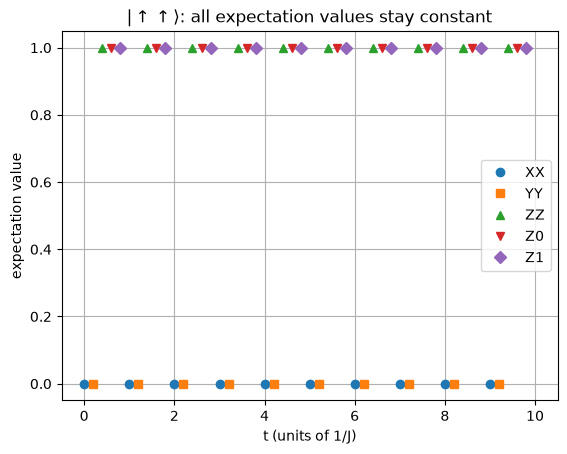

In [6]:
# Visualizing the results

t = np.array(results.times)

markers = ["o", "s", "^", "v", "D"]
for i, (name, values) in enumerate(results.metrics.items()):
    plt.plot(
        t,
        values,
        label=name,
        marker=markers[i],
        markevery=(i * 20, 100),
        linestyle="none",
    )

plt.xlabel("t (units of 1/J)")
plt.ylabel("expectation value")
plt.title(r"$|\uparrow\uparrow\rangle$: all expectation values stay constant")
plt.legend()
plt.grid()
plt.show()

As predicted, all expectation values stay constant. What about the energy and the total $Z$? Both are conserved for *any* initial state, so checking them is a good test that the emulation is consistent. We build both from the separate metrics:

Total Z conserved? True
Energy conserved? True
Counts: {'00': 1000}


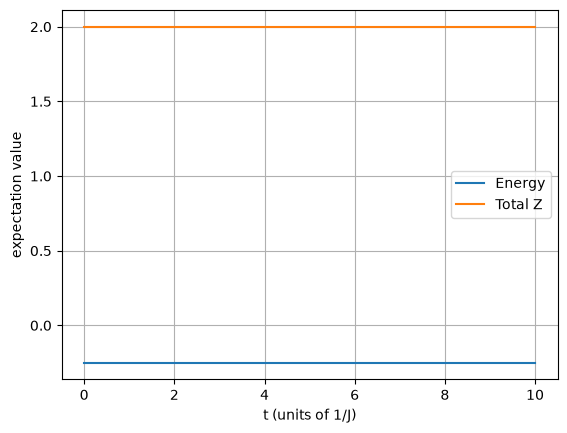

In [7]:
# Convert the metric results into NumPy arrays
XX = np.array(results.metrics["XX"])
YY = np.array(results.metrics["YY"])
ZZ = np.array(results.metrics["ZZ"])
Z0 = np.array(results.metrics["Z0"])
Z1 = np.array(results.metrics["Z1"])

# Build the energy and total Z from the separate metrics
E = -J / 4 * (XX + YY + ZZ)
total_Z = Z0 + Z1

# Consistency checks: both should stay at their initial value
print("Total Z conserved?", np.allclose(total_Z, total_Z[0]))
print("Energy conserved?", np.allclose(E, E[0]))

# |00⟩ is an eigenstate, so every shot should return 00
print("Counts:", results.counts)

plt.plot(t, E, label="Energy")
plt.plot(t, total_Z, label="Total Z")
plt.xlabel("t (units of 1/J)")
plt.ylabel("expectation value")
plt.grid()
plt.legend()
plt.show()

## **Experiment 2: Dynamics of the |↑↓⟩ state** 


Unlike the $|\uparrow\uparrow\rangle$ state, the $|\uparrow\downarrow\rangle$ state is not an eigenstate of the Heisenberg Hamiltonian, and would show time-dependent expectation values $\langle Z_0 \rangle$ and $\langle Z_1 \rangle$.

One can determine this by writing $|\uparrow\downarrow\rangle$ in the triplet and singlet basis of the Hamiltonian, time evolving each of the terms and calculating the expectation values. Working this out, one would see that

$$\langle Z_0 \rangle = \cos(Jt), \qquad \langle Z_1 \rangle = -\cos(Jt).$$

Let's see if this agrees with our emulation!

**Preparing the state.** As we mentioned, our emulator always starts in the $|\uparrow\uparrow\rangle$ state, so we first need to prepare the $|\uparrow\downarrow\rangle$ state using analog pulses. In other words, we time evolve under different Hamiltonians for different times to get to the state that we want. For example, to get to $|\uparrow\downarrow\rangle$ from $|\uparrow\uparrow\rangle$, we time evolve under the $I \otimes X$ operator for $t = \pi/2$:

$$e^{-i(I \otimes X)\pi/2}\,|\uparrow\uparrow\rangle = -i\,|\uparrow\downarrow\rangle .$$

The factor $-i$ is a global phase, so it has no effect on any measurement.

> **Note:** Here $t$ is measured from the start of the Heisenberg evolution. The emulator's `results.times` also includes the preparation step, so we shift the time axis by $\pi/2$ before comparing.

In [8]:
# Check the preparation alone: flipping qubit 1 should give |↑↓⟩ = "01"
t_prep = np.pi / 2

prep_circuit = AnalogCircuit()
prep_circuit.evolve(duration=t_prep, gate=AnalogGate(hamiltonian=I @ X))
prep_circuit.measure()

prep_task = Task(program=prep_circuit, args=TaskArgsAnalog(n_shots=1000))
prep_results = QutipBackend().run(task=prep_task)

print("Counts:", prep_results.counts)
print("Prepared |↑↓⟩?", prep_results.counts == {"01": 1000})

Counts: {'01': 1000}
Prepared |↑↓⟩? True


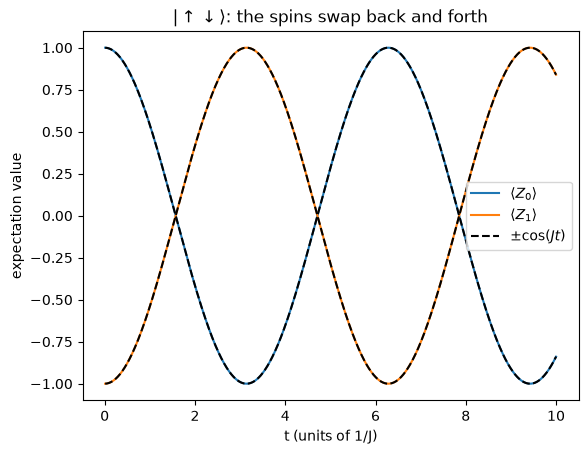

In [9]:
# Prepare |↑↓⟩ (flip qubit 1), then evolve under the Heisenberg Hamiltonian
t_prep = np.pi / 2

circuit = AnalogCircuit()
circuit.evolve(duration=t_prep, gate=AnalogGate(hamiltonian=I @ X))
circuit.evolve(duration=10, gate=AnalogGate(hamiltonian=H))
circuit.measure()

# One metric per Pauli string
metrics = {
    "XX": Expectation(operator=X @ X),
    "YY": Expectation(operator=Y @ Y),
    "ZZ": Expectation(operator=Z @ Z),
    "Z0": Expectation(operator=Z @ I),  # Z on qubit 0
    "Z1": Expectation(operator=I @ Z),  # Z on qubit 1
    "EntropyVN0": EntanglementEntropyVN(qreg=[0]),  # von Neumann entropy of qubit 0
}

# Emulation settings
args = TaskArgsAnalog(n_shots=1000, metrics=metrics, dt=0.01)
task = Task(program=circuit, args=args)
results = QutipBackend().run(task=task)

# Keep only the Heisenberg part, and restart its clock at t = 0
t_all = np.array(results.times)
after_prep = t_all > t_prep
t = t_all[after_prep] - t_prep

Z0 = np.array(results.metrics["Z0"])[after_prep]
Z1 = np.array(results.metrics["Z1"])[after_prep]

plt.plot(t, Z0, label=r"$\langle Z_0 \rangle$")
plt.plot(t, Z1, label=r"$\langle Z_1 \rangle$")
plt.plot(t, np.cos(J * t), "k--", label=r"$\pm\cos(Jt)$")
plt.plot(t, -np.cos(J * t), "k--")
plt.xlabel("t (units of 1/J)")
plt.ylabel("expectation value")
plt.title(r"$|\uparrow\downarrow\rangle$: the spins swap back and forth")
plt.legend()
plt.show()

To quantify entanglement, we can compute the von Neumann entropy of a qubit. For qubit 0, the von Neumann entropy is defined as

$$S = -\mathrm{Tr}\left(\rho_0 \ln \rho_0\right), \qquad \rho_0 = \mathrm{Tr}_1 |\psi\rangle\langle\psi| ,$$

where $\rho_0$ is the reduced density matrix of qubit 0. This tells us how entangled the state is: $S = 0$ for a product state and $S = \ln 2$ for a maximally entangled one. For the $|\uparrow\downarrow\rangle$ state, we would expect the state to start as not entangled, then slowly become more entangled, reaching maximal entanglement at $Jt = \pi/2$, and disentangle again at $Jt = \pi$, when the swap is complete. The theoretical formula is:

$$S(t) = -p \ln p - (1-p) \ln(1-p), \qquad p = \cos^2(Jt/2).$$

We already added the entanglement entropy metric to our experiment, so we just need to plot it now.

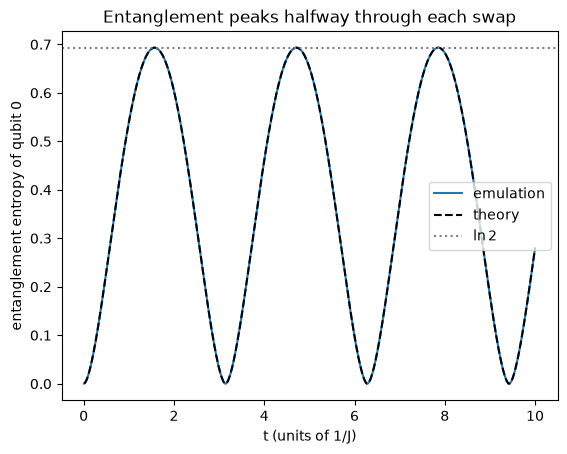

In [10]:
S0 = np.array(results.metrics["EntropyVN0"])[after_prep]

# Theory: S(t) = -p ln p - (1 - p) ln(1 - p), with p = cos²(Jt/2)
p = np.clip(np.cos(J * t / 2) ** 2, 1e-12, 1 - 1e-12)  # avoid ln(0)
S_theory = -p * np.log(p) - (1 - p) * np.log(1 - p)

plt.plot(t, S0, label="emulation")
plt.plot(t, S_theory, "k--", label="theory")
plt.axhline(np.log(2), color="gray", linestyle=":", label=r"$\ln 2$")
plt.xlabel("t (units of 1/J)")
plt.ylabel("entanglement entropy of qubit 0")
plt.title("Entanglement peaks halfway through each swap")
plt.legend()
plt.show()

To conclude our experiment let's run our consistency checks making sure that the energy, as well as the total Z are conserved.

Total Z conserved? True
Energy conserved? True
Counts: {'10': 916, '01': 84}


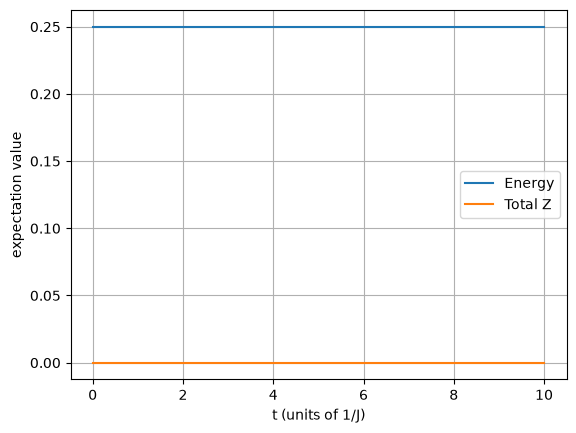

In [11]:
# Restrict our Expectation values after the state preparation as usual.

XX = np.array(results.metrics["XX"])[after_prep]
YY = np.array(results.metrics["YY"])[after_prep]
ZZ = np.array(results.metrics["ZZ"])[after_prep]

E = -J / 4 * (XX + YY + ZZ)
total_Z = Z0 + Z1

# Consistency checks: both should stay at their initial value
print("Total Z conserved?", np.allclose(total_Z, total_Z[0]))
print("Energy conserved?", np.allclose(E, E[0]))

print("Counts:", results.counts)

plt.plot(t, E, label="Energy")
plt.plot(t, total_Z, label="Total Z")
plt.xlabel("t (units of 1/J)")
plt.ylabel("expectation value")
plt.grid()
plt.legend()
plt.show()

## **Experiment 3: Preparing the Singlet and Triplet States**

A strong capability of the analog emulator is that it lets us experiment with which sequence of analog pulses prepares a given state. On real quantum hardware, this matters because we can only apply the interactions and fields the device physically provides, each for a chosen duration, so preparing a target state means finding the right pulse sequence. Testing sequences on an emulator first saves valuable hardware time.

We have already seen how to prepare $|\uparrow\downarrow\rangle$ from $|\uparrow\uparrow\rangle$. Now, starting again from $|\uparrow\uparrow\rangle$, let's prepare the triplet state $T_0$ and the singlet state $S$, which are both eigenstates of the Heisenberg Hamiltonian:

$$T_0 = \frac{|\uparrow\downarrow\rangle + |\downarrow\uparrow\rangle}{\sqrt{2}}, \qquad S = \frac{|\uparrow\downarrow\rangle - |\downarrow\uparrow\rangle}{\sqrt{2}} .$$

After preparing each one, we keep evolving under the Heisenberg Hamiltonian and check that they really are eigenstates: all expectation values should stay frozen. To tell them apart, we measure the spin correlation $\langle \mathbf{S}_0 \cdot \mathbf{S}_1 \rangle$, which is $+1/4$ for $T_0$ and $-3/4$ for $S$.

To prepare $T_0$ and $S$, we use a sequence of three pulses:

1. **Flip qubit 1** with $I \otimes X$ for $t = \pi/2$: $|\uparrow\uparrow\rangle \to |\uparrow\downarrow\rangle$.
2. **Evolve under the Heisenberg Hamiltonian** until $Jt = \pi/2$. The swap is halfway done, giving an equal superposition $(|\uparrow\downarrow\rangle + i|\downarrow\uparrow\rangle)/\sqrt{2}$, but with the wrong relative phase ($i$).
3. **Fix the phase with a $Z$ field on qubit 0** for a time $\tau$. This multiplies the relative phase by $e^{2i\tau}$ without changing the amplitudes, so the phase becomes $i\,e^{2i\tau} = e^{i(\pi/2 + 2\tau)}$:
   - $\tau = \pi/4$ gives phase $-1$, the singlet $S$;
   - $\tau = 3\pi/4$ gives phase $+1$, the triplet $T_0$.

Finally, we keep evolving under the Heisenberg Hamiltonian. Since both states are eigenstates, everything should stay frozen: $\langle Z_0 \rangle = \langle Z_1 \rangle = 0$, the entanglement entropy stays at $\ln 2$, and $\langle \mathbf{S}_0 \cdot \mathbf{S}_1 \rangle = -3/4$ for $S$ and $+1/4$ for $T_0$.

Let's implement this!

In [12]:
def singlet_triplet_circuit(tau, t_freeze=10):
    """Prepare the singlet (tau = π/4) or the triplet T0 (tau = 3π/4),
    then evolve under the Heisenberg Hamiltonian to check it stays frozen.

    Returns the circuit and the total preparation time.
    """
    t_flip = np.pi / 2  # I⊗X: |↑↑⟩ → |↑↓⟩
    t_half_swap = np.pi / (2 * J)  # Heisenberg until Jt = π/2

    circuit = AnalogCircuit()
    circuit.evolve(duration=t_flip, gate=AnalogGate(hamiltonian=I @ X))
    circuit.evolve(duration=t_half_swap, gate=AnalogGate(hamiltonian=H))
    circuit.evolve(duration=tau, gate=AnalogGate(hamiltonian=Z @ I))
    circuit.evolve(
        duration=t_freeze, gate=AnalogGate(hamiltonian=H)
    )  # should stay constant
    circuit.measure()

    t_prep = t_flip + t_half_swap + tau
    return circuit, t_prep


# Create the triplet and the singlet circuits
singlet_circuit, t_prep_S = singlet_triplet_circuit(tau=np.pi / 4)
triplet_circuit, t_prep_T = singlet_triplet_circuit(tau=3 * np.pi / 4)

In [13]:
# Singlet state checks

args = TaskArgsAnalog(n_shots=1000, metrics=metrics, dt=0.01)
results = QutipBackend().run(task=Task(program=singlet_circuit, args=args))

t_all = np.array(results.times)
after_prep = t_all > t_prep_S
t = t_all[after_prep] - t_prep_S

Z0 = np.array(results.metrics["Z0"])[after_prep]
Z1 = np.array(results.metrics["Z1"])[after_prep]
XX = np.array(results.metrics["XX"])[after_prep]
YY = np.array(results.metrics["YY"])[after_prep]
ZZ = np.array(results.metrics["ZZ"])[after_prep]
S0 = np.array(results.metrics["EntropyVN0"])[after_prep]

S0S1 = (XX + YY + ZZ) / 4

print("Singlet state checks:")
print("<S0.S1> =", S0S1[0], "(expected -0.75)")
print("<Z0> =", Z0[0], "and <Z1> =", Z1[0], "(expected 0)")
print("Entropy =", S0[0], "(expected ln 2 =", np.log(2), ")")
print("S0.S1 frozen?", np.allclose(S0S1, S0S1[0]))
print("Counts:", results.counts)

Singlet state checks:
<S0.S1> = -0.7499999999989727 (expected -0.75)
<Z0> = -1.2648354450472965e-06 and <Z1> = 1.2648366797263222e-06 (expected 0)
Entropy = 0.6931471805585281 (expected ln 2 = 0.6931471805599453 )
S0.S1 frozen? True
Counts: {'10': 468, '01': 532}


In [14]:
# Triplet State checks:

args = TaskArgsAnalog(n_shots=1000, metrics=metrics, dt=0.01)
results = QutipBackend().run(task=Task(program=triplet_circuit, args=args))

t_all = np.array(results.times)
after_prep = t_all > t_prep_T
t = t_all[after_prep] - t_prep_T

Z0 = np.array(results.metrics["Z0"])[after_prep]
Z1 = np.array(results.metrics["Z1"])[after_prep]
XX = np.array(results.metrics["XX"])[after_prep]
YY = np.array(results.metrics["YY"])[after_prep]
ZZ = np.array(results.metrics["ZZ"])[after_prep]
S0 = np.array(results.metrics["EntropyVN0"])[after_prep]

S0S1 = (XX + YY + ZZ) / 4

print("Triplet T0 state checks:")
print("<S0.S1> =", S0S1[0], "(expected +0.25)")
print("<Z0> =", Z0[0], "and <Z1> =", Z1[0], "(expected 0)")
print("Entropy =", S0[0], "(expected ln 2 =", np.log(2), ")")
print("S0.S1 frozen?", np.allclose(S0S1, S0S1[0]))
print("Counts:", results.counts)

Triplet T0 state checks:
<S0.S1> = 0.24999999999398945 (expected +0.25)
<Z0> = -1.3101327853703992e-06 and <Z1> = 1.310134020049425e-06 (expected 0)
Entropy = 0.6931471805584698 (expected ln 2 = 0.6931471805599453 )
S0.S1 frozen? True
Counts: {'01': 494, '10': 506}


All of our checks have passed: we successfully prepared the triplet and singlet states. It's interesting to note that their counts are roughly equal, showing that we can't tell these states apart with $Z$ measurements, because a $Z$ measurement is blind to the relative phase. We can, however, see the difference by measuring spin correlations: $\langle \mathbf{S}_0 \cdot \mathbf{S}_1 \rangle = -3/4$ for the singlet and $+1/4$ for the triplet, since it includes the $XX$ and $YY$ terms, which are sensitive to the phase.